In [78]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [79]:
# Windows에 설치된 맑은 고딕을 사용합니다.
plt.rcParams["font.family"] = "Malgun Gothic"

# 일부 글꼴에서 음수 기호가 깨지는 문제를 피합니다.
plt.rcParams["axes.unicode_minus"] = False

In [80]:
data_0 = "C:\\wind\\CARE_To_Compare\\CARE_To_Compare\\Wind Farm A\\datasets\\0.csv"  
data_3 = "C:\\wind\\CARE_To_Compare\\CARE_To_Compare\\Wind Farm A\\datasets\\3.csv"  
columns_info = "C:\\wind\\CARE_To_Compare\\CARE_To_Compare\\Wind Farm A\\feature_description.csv"

# 전체 워크플로우 (7단계)
1.	불러오기 — pd.read_csv()
2.	구조 파악 — shape, head, info
3.	결측치 처리 — isna, drop(고결측 컬럼), fillna(중앙값)
4.	이상치·중복 — IQR, duplicated, drop_duplicates
5.	통계·상관 — describe, groupby, corr
6.	시각화 — histplot, boxplot, heatmap
7.	리포트 — 개요·전처리·발견·결론 4단 구조

포르투갈 육상 풍력단지 내 한개의 풍력발전기 1년치 DATA

In [100]:
#1.	불러오기 — pd.read_csv()
df0=pd.read_csv(data_0,sep=';')
df3=pd.read_csv(data_3,sep=';')
info = pd.read_csv(columns_info, sep=';',encoding='utf-8')

In [101]:
#2.	구조 파악 — shape, head, info
print(df0.shape)


(54986, 86)


In [102]:
df0.columns.tolist()

['time_stamp',
 'asset_id',
 'id',
 'train_test',
 'status_type_id',
 'sensor_0_avg',
 'sensor_1_avg',
 'sensor_2_avg',
 'wind_speed_3_avg',
 'wind_speed_4_avg',
 'wind_speed_3_max',
 'wind_speed_3_min',
 'wind_speed_3_std',
 'sensor_5_avg',
 'sensor_5_max',
 'sensor_5_min',
 'sensor_5_std',
 'sensor_6_avg',
 'sensor_7_avg',
 'sensor_8_avg',
 'sensor_9_avg',
 'sensor_10_avg',
 'sensor_11_avg',
 'sensor_12_avg',
 'sensor_13_avg',
 'sensor_14_avg',
 'sensor_15_avg',
 'sensor_16_avg',
 'sensor_17_avg',
 'sensor_18_avg',
 'sensor_18_max',
 'sensor_18_min',
 'sensor_18_std',
 'sensor_19_avg',
 'sensor_20_avg',
 'sensor_21_avg',
 'sensor_22_avg',
 'sensor_23_avg',
 'sensor_24_avg',
 'sensor_25_avg',
 'sensor_26_avg',
 'reactive_power_27_avg',
 'reactive_power_27_max',
 'reactive_power_27_min',
 'reactive_power_27_std',
 'reactive_power_28_avg',
 'reactive_power_28_max',
 'reactive_power_28_min',
 'reactive_power_28_std',
 'power_29_avg',
 'power_29_max',
 'power_29_min',
 'power_29_std',
 'p

In [103]:
# 전체 컬럼명을 한글로 변경
df0 = df0.rename(columns={
    'time_stamp': '일시',
    'asset_id': '풍력발전기_ID',
    'id': '기록_ID',
    'train_test': '학습_예측_구분',
    'status_type_id': '운전상태_ID',

    'sensor_0_avg': '외기온도_평균',
    'sensor_1_avg': '절대풍향_평균',
    'sensor_2_avg': '상대풍향_평균',

    'wind_speed_3_avg': '풍속_평균',
    'wind_speed_4_avg': '추정풍속_평균',
    'wind_speed_3_max': '풍속_최대',
    'wind_speed_3_min': '풍속_최소',
    'wind_speed_3_std': '풍속_표준편차',

    'sensor_5_avg': '피치각도_평균',
    'sensor_5_max': '피치각도_최대',
    'sensor_5_min': '피치각도_최소',
    'sensor_5_std': '피치각도_표준편차',

    'sensor_6_avg': '허브제어기온도_평균',
    'sensor_7_avg': '나셀상부제어기온도_평균',
    'sensor_8_avg': 'VCS구역_초크코일온도_평균',
    'sensor_9_avg': 'VCP보드온도_평균',
    'sensor_10_avg': 'VCS냉각수온도_평균',
    'sensor_11_avg': '기어박스_고속축베어링온도_평균',
    'sensor_12_avg': '기어박스오일온도_평균',
    'sensor_13_avg': '발전기베어링2_구동측온도_평균',
    'sensor_14_avg': '발전기베어링1_비구동측온도_평균',
    'sensor_15_avg': '발전기고정자권선_1상온도_평균',
    'sensor_16_avg': '발전기고정자권선_2상온도_평균',
    'sensor_17_avg': '발전기고정자권선_3상온도_평균',

    'sensor_18_avg': '발전기회전속도_평균',
    'sensor_18_max': '발전기회전속도_최대',
    'sensor_18_min': '발전기회전속도_최소',
    'sensor_18_std': '발전기회전속도_표준편차',

    'sensor_19_avg': '스플릿링실온도_평균',
    'sensor_20_avg': '버스바구역온도_평균',
    'sensor_21_avg': '계통측인버터_IGBT드라이버온도_평균',
    'sensor_22_avg': '실제위상차_평균',
    'sensor_23_avg': '1상전류_평균',
    'sensor_24_avg': '2상전류_평균',
    'sensor_25_avg': '3상전류_평균',
    'sensor_26_avg': '전력망주파수_평균',

    'reactive_power_27_avg': '계통용량성무효전력_가능값_평균',
    'reactive_power_27_max': '계통용량성무효전력_가능값_최대',
    'reactive_power_27_min': '계통용량성무효전력_가능값_최소',
    'reactive_power_27_std': '계통용량성무효전력_가능값_표준편차',

    'reactive_power_28_avg': '계통유도성무효전력_가능값_평균',
    'reactive_power_28_max': '계통유도성무효전력_가능값_최대',
    'reactive_power_28_min': '계통유도성무효전력_가능값_최소',
    'reactive_power_28_std': '계통유도성무효전력_가능값_표준편차',

    'power_29_avg': '계통유효전력_가능값_평균',
    'power_29_max': '계통유효전력_가능값_최대',
    'power_29_min': '계통유효전력_가능값_최소',
    'power_29_std': '계통유효전력_가능값_표준편차',

    'power_30_avg': '전력망출력_평균',
    'power_30_max': '전력망출력_최대',
    'power_30_min': '전력망출력_최소',
    'power_30_std': '전력망출력_표준편차',

    'sensor_31_avg': '전력망무효전력_평균',
    'sensor_31_max': '전력망무효전력_최대',
    'sensor_31_min': '전력망무효전력_최소',
    'sensor_31_std': '전력망무효전력_표준편차',

    'sensor_32_avg': '1상전압_평균',
    'sensor_33_avg': '2상전압_평균',
    'sensor_34_avg': '3상전압_평균',

    'sensor_35_avg': '회전자측인버터_1상IGBT드라이버온도_평균',
    'sensor_36_avg': '회전자측인버터_2상IGBT드라이버온도_평균',
    'sensor_37_avg': '회전자측인버터_3상IGBT드라이버온도_평균',

    'sensor_38_avg': '고압변압기_L1상온도_평균',
    'sensor_39_avg': '고압변압기_L2상온도_평균',
    'sensor_40_avg': '고압변압기_L3상온도_평균',

    'sensor_41_avg': '유압장치오일온도_평균',
    'sensor_42_avg': '나셀방향_평균',
    'sensor_43_avg': '나셀온도_평균',

    'sensor_44': '발전기분리상태_유효에너지',
    'sensor_45': '발전기델타결선상태_유효에너지',
    'sensor_46': '발전기스타결선상태_유효에너지',
    'sensor_47': '발전기분리상태_무효에너지',
    'sensor_48': '발전기델타결선상태_무효에너지',
    'sensor_49': '발전기스타결선상태_무효에너지',
    'sensor_50': '전체유효에너지',
    'sensor_51': '전체무효에너지',

    'sensor_52_avg': '로터회전속도_평균',
    'sensor_52_max': '로터회전속도_최대',
    'sensor_52_min': '로터회전속도_최소',
    'sensor_52_std': '로터회전속도_표준편차',

    'sensor_53_avg': '노즈콘내부온도_평균'
})

# 변경된 컬럼명 확인
df0.columns.tolist()

['일시',
 '풍력발전기_ID',
 '기록_ID',
 '학습_예측_구분',
 '운전상태_ID',
 '외기온도_평균',
 '절대풍향_평균',
 '상대풍향_평균',
 '풍속_평균',
 '추정풍속_평균',
 '풍속_최대',
 '풍속_최소',
 '풍속_표준편차',
 '피치각도_평균',
 '피치각도_최대',
 '피치각도_최소',
 '피치각도_표준편차',
 '허브제어기온도_평균',
 '나셀상부제어기온도_평균',
 'VCS구역_초크코일온도_평균',
 'VCP보드온도_평균',
 'VCS냉각수온도_평균',
 '기어박스_고속축베어링온도_평균',
 '기어박스오일온도_평균',
 '발전기베어링2_구동측온도_평균',
 '발전기베어링1_비구동측온도_평균',
 '발전기고정자권선_1상온도_평균',
 '발전기고정자권선_2상온도_평균',
 '발전기고정자권선_3상온도_평균',
 '발전기회전속도_평균',
 '발전기회전속도_최대',
 '발전기회전속도_최소',
 '발전기회전속도_표준편차',
 '스플릿링실온도_평균',
 '버스바구역온도_평균',
 '계통측인버터_IGBT드라이버온도_평균',
 '실제위상차_평균',
 '1상전류_평균',
 '2상전류_평균',
 '3상전류_평균',
 '전력망주파수_평균',
 '계통용량성무효전력_가능값_평균',
 '계통용량성무효전력_가능값_최대',
 '계통용량성무효전력_가능값_최소',
 '계통용량성무효전력_가능값_표준편차',
 '계통유도성무효전력_가능값_평균',
 '계통유도성무효전력_가능값_최대',
 '계통유도성무효전력_가능값_최소',
 '계통유도성무효전력_가능값_표준편차',
 '계통유효전력_가능값_평균',
 '계통유효전력_가능값_최대',
 '계통유효전력_가능값_최소',
 '계통유효전력_가능값_표준편차',
 '전력망출력_평균',
 '전력망출력_최대',
 '전력망출력_최소',
 '전력망출력_표준편차',
 '전력망무효전력_평균',
 '전력망무효전력_최대',
 '전력망무효전력_최소',
 '전력망무효전력_표준편차',
 '1상전압_평균',
 '2상전압_평균',
 '3상전압_평균',
 

In [104]:
print("컬럼 개수:", len(df0.columns.tolist()))

컬럼 개수: 86


In [105]:
df0.head()

,일시,풍력발전기_ID,기록_ID,학습_예측_구분,운전상태_ID,외기온도_평균,절대풍향_평균,상대풍향_평균,풍속_평균,추정풍속_평균,...,발전기분리상태_무효에너지,발전기델타결선상태_무효에너지,발전기스타결선상태_무효에너지,전체유효에너지,전체무효에너지,로터회전속도_평균,로터회전속도_최대,로터회전속도_최소,로터회전속도_표준편차,노즈콘내부온도_평균
0,2022-08-04 06:10:00,0,0,train,0,22.0,302.9,129.4,1.7,1.7,...,-496.0,0.0,0.0,-1280.0,-496.0,0.0,0.0,0.0,0.0,26.0
1,2022-08-04 06:20:00,0,1,train,0,22.0,307.1,133.6,1.7,1.7,...,-490.0,0.0,0.0,-1278.0,-490.0,0.0,0.0,0.0,0.0,25.0
2,2022-08-04 06:30:00,0,2,train,0,22.0,340.6,167.1,0.9,0.9,...,-490.0,0.0,0.0,-1356.0,-490.0,0.0,0.0,0.0,0.0,25.0
3,2022-08-04 06:40:00,0,3,train,0,22.0,124.4,-49.1,1.5,1.5,...,-509.0,0.0,0.0,-1274.0,-509.0,0.0,0.0,0.0,0.0,26.0
4,2022-08-04 06:50:00,0,4,train,0,22.0,66.2,-107.3,1.0,1.0,...,-499.0,0.0,0.0,-1284.0,-499.0,0.0,0.0,0.0,0.0,26.0


In [106]:
df0.info()

<class 'pandas.DataFrame'>
RangeIndex: 54986 entries, 0 to 54985
Data columns (total 86 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   일시                       54986 non-null  str    
 1   풍력발전기_ID                 54986 non-null  int64  
 2   기록_ID                    54986 non-null  int64  
 3   학습_예측_구분                 54986 non-null  str    
 4   운전상태_ID                  54986 non-null  int64  
 5   외기온도_평균                  54986 non-null  float64
 6   절대풍향_평균                  54986 non-null  float64
 7   상대풍향_평균                  54986 non-null  float64
 8   풍속_평균                    54986 non-null  float64
 9   추정풍속_평균                  54986 non-null  float64
 10  풍속_최대                    54986 non-null  float64
 11  풍속_최소                    54986 non-null  float64
 12  풍속_표준편차                  54986 non-null  float64
 13  피치각도_평균                  54986 non-null  float64
 14  피치각도_최대                  54986 no

In [107]:
#3.	결측치 처리 — isna, drop(고결측 컬럼), fillna(중앙값)


In [108]:
print("결측치 처리 전:", df0.isna().sum().sum()) #결측치 확인

결측치 처리 전: 2


In [109]:
# 숫자형 컬럼의 결측치를 각 컬럼의 중앙값으로 채우기
df0 = df0.fillna(df0.median(numeric_only=True))
print("결측치 처리 후 : ", df0.isna().sum().sum())

결측치 처리 후 :  0


In [110]:
#4. 이상치·중복 — IQR, duplicated, drop_duplicates

In [111]:
# 중복 행 개수 확인
df0.duplicated().sum()
print("중복 행 개수: ", df0.duplicated().sum()) 

중복 행 개수:  0


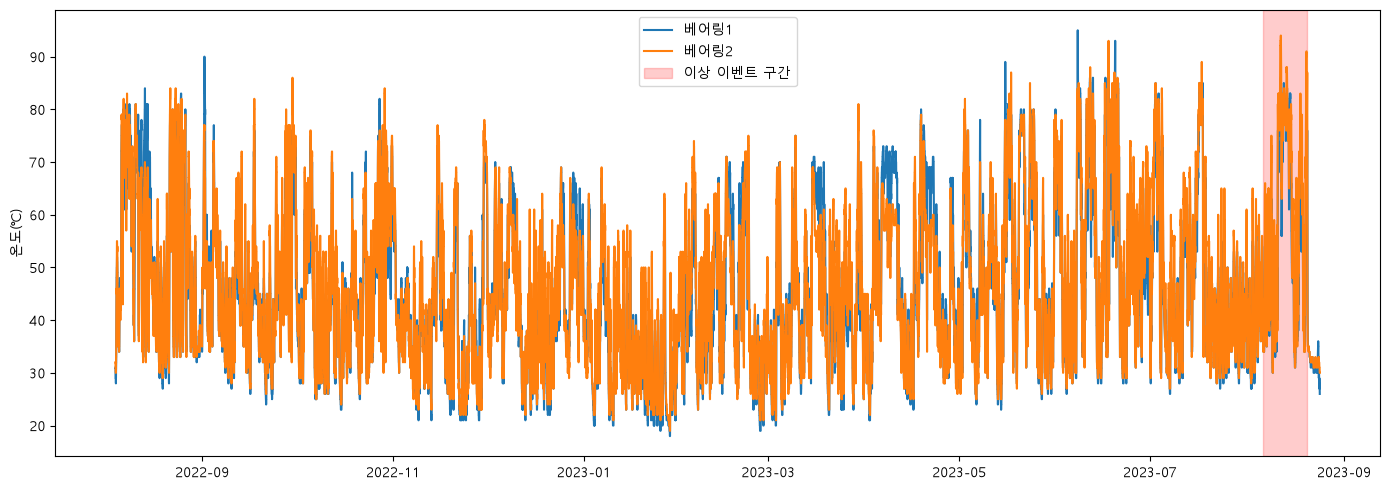

In [117]:
# 일시를 날짜·시간 자료형으로 변경
df0['일시'] = pd.to_datetime(df0['일시'])

# 시간순 정렬
df0 = df0.sort_values('일시')

# 두 베어링 온도 그리기
plt.figure(figsize=(14, 5))

plt.plot(
    df0['일시'],
    df0['발전기베어링1_비구동측온도_평균'],
    label='베어링1'
)

plt.plot(
    df0['일시'],
    df0['발전기베어링2_구동측온도_평균'],
    label='베어링2'
)

# 제공자가 지정한 이상 이벤트 구간 표시
plt.axvspan(
    pd.Timestamp('2023-08-06 06:10:00'),
    pd.Timestamp('2023-08-20 06:10:00'),
    color='red',
    alpha=0.2,
    label='이상 이벤트 구간'
)

plt.ylabel('온도(℃)')
plt.legend()
plt.tight_layout()
plt.show()

In [112]:
#이상치 찾기

| `0` | 정상 운전
| `1` | 출력 제한 운전 
| `2` | 재가동을 기다리는 대기 상태 
| `3` | 정비 상태 | 1,207 |
| `4` | 고장 또는 다른 이유로 정지 | 6,239 |
| `5` | 기타 운전 상태

In [113]:
# 운전 상태별 기록 수
df0['운전상태_ID'].value_counts()

운전상태_ID
0    47540
4     6239
3     1207
Name: count, dtype: int64

In [ ]:
##

In [116]:
normal = df0['운전상태_ID'] == 0 
normal.head()

0    True
1    True
2    True
3    True
4    True
Name: 운전상태_ID, dtype: bool

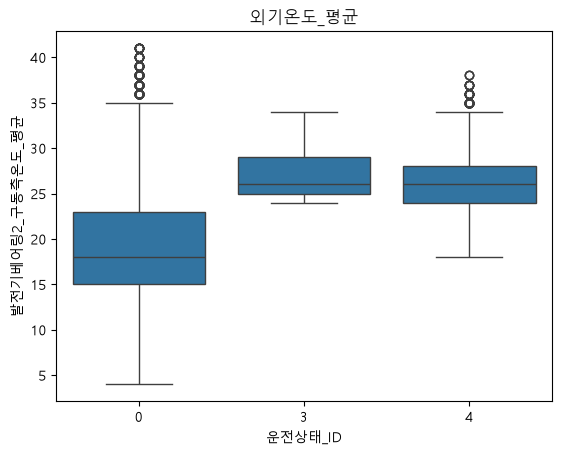

In [134]:
sns.boxplot(
    x='운전상태_ID',
    y='외기온도_평균',
    data=df0)

plt.title('외기온도_평균')
plt.xlabel('운전상태_ID')
plt.ylabel('발전기베어링2_구동측온도_평균')
plt.show()


In [137]:
#5.	통계·상관 — describe, groupby, corr


In [ ]:
round(df0.describe(), 2)

In [140]:
# 운전상태_ID와의 상관계수 계산
corr = df0.corr(numeric_only=True)['운전상태_ID'].drop('운전상태_ID')

# 양수·음수 관계없이 절댓값이 큰 순서로 보기
corr.loc[corr.abs().sort_values(ascending=False).index].head(10)

외기온도_평균           0.410402
나셀온도_평균           0.384941
노즈콘내부온도_평균        0.358603
스플릿링실온도_평균        0.332705
허브제어기온도_평균        0.317095
나셀상부제어기온도_평균      0.315095
VCP보드온도_평균        0.311970
유압장치오일온도_평균       0.290330
버스바구역온도_평균        0.253422
고압변압기_L3상온도_평균    0.240779
Name: 운전상태_ID, dtype: float64

In [ ]:
df0.groupby('운전상태_ID')['외기온도_평균'].mean()

운전상태_ID
0    19.201599
3    27.112676
4    25.997275
Name: 외기온도_평균, dtype: float64

In [145]:
df0.groupby('운전상태_ID')['발전기베어링1_비구동측온도_평균'].mean()

운전상태_ID
0    44.494720
3    53.495443
4    53.234493
Name: 발전기베어링1_비구동측온도_평균, dtype: float64

In [151]:
df0.groupby('운전상태_ID')['발전기베어링2_구동측온도_평균'].mean()

운전상태_ID
0    45.633025
3    55.300746
4    55.022439
Name: 발전기베어링2_구동측온도_평균, dtype: float64

| `0` | 정상 운전
| `1` | 출력 제한 운전 
| `2` | 재가동을 기다리는 대기 상태 
| `3` | 정비 상태 | 1,207 |
| `4` | 고장 또는 다른 이유로 정지 | 6,239 |
| `5` | 기타 운전 상태

In [ ]:
#sns.histplot
#sns.boxeplot

In [144]:
#6.	시각화 — histplot, boxplot, heatmap
#7.	리포트 — 개요·전처리·발견·결론 4단 구조

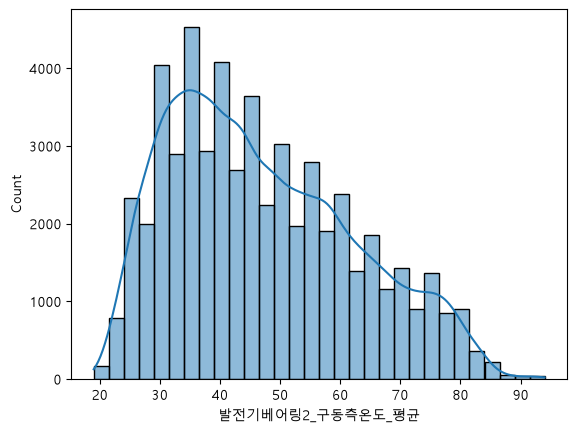

In [166]:
sns.histplot(
    df0['발전기베어링2_구동측온도_평균'],
    bins=30,
    kde=True
)
plt.show()

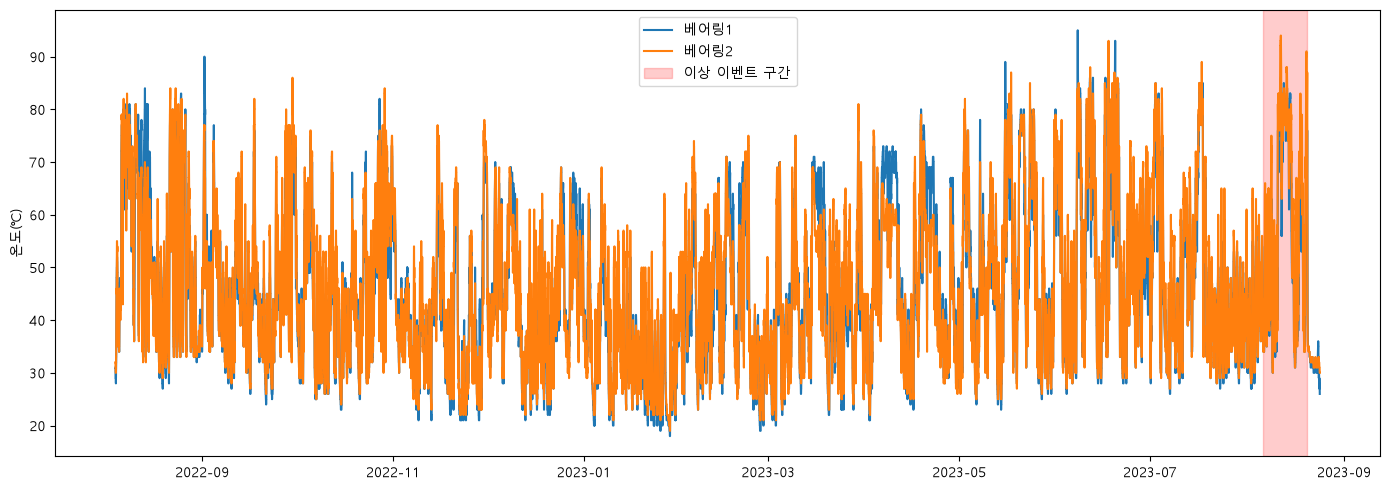

In [173]:
# 일시를 날짜·시간 자료형으로 변경
df0['일시'] = pd.to_datetime(df0['일시'])

# 시간순 정렬
df0 = df0.sort_values('일시')

# 두 베어링 온도 그리기
plt.figure(figsize=(14, 5))

plt.plot(
    df0['일시'],
    df0['발전기베어링1_비구동측온도_평균'],
    label='베어링1'
)

plt.plot(
    df0['일시'],
    df0['발전기베어링2_구동측온도_평균'],
    label='베어링2'
)

# 제공자가 지정한 이상 이벤트 구간 표시
plt.axvspan(
    pd.Timestamp('2023-08-06 06:10:00'),
    pd.Timestamp('2023-08-20 06:10:00'),
    color='red',
    alpha=0.2,
    label='이상 이벤트 구간'
)

plt.ylabel('온도(℃)')
plt.legend()
plt.tight_layout()
plt.show()

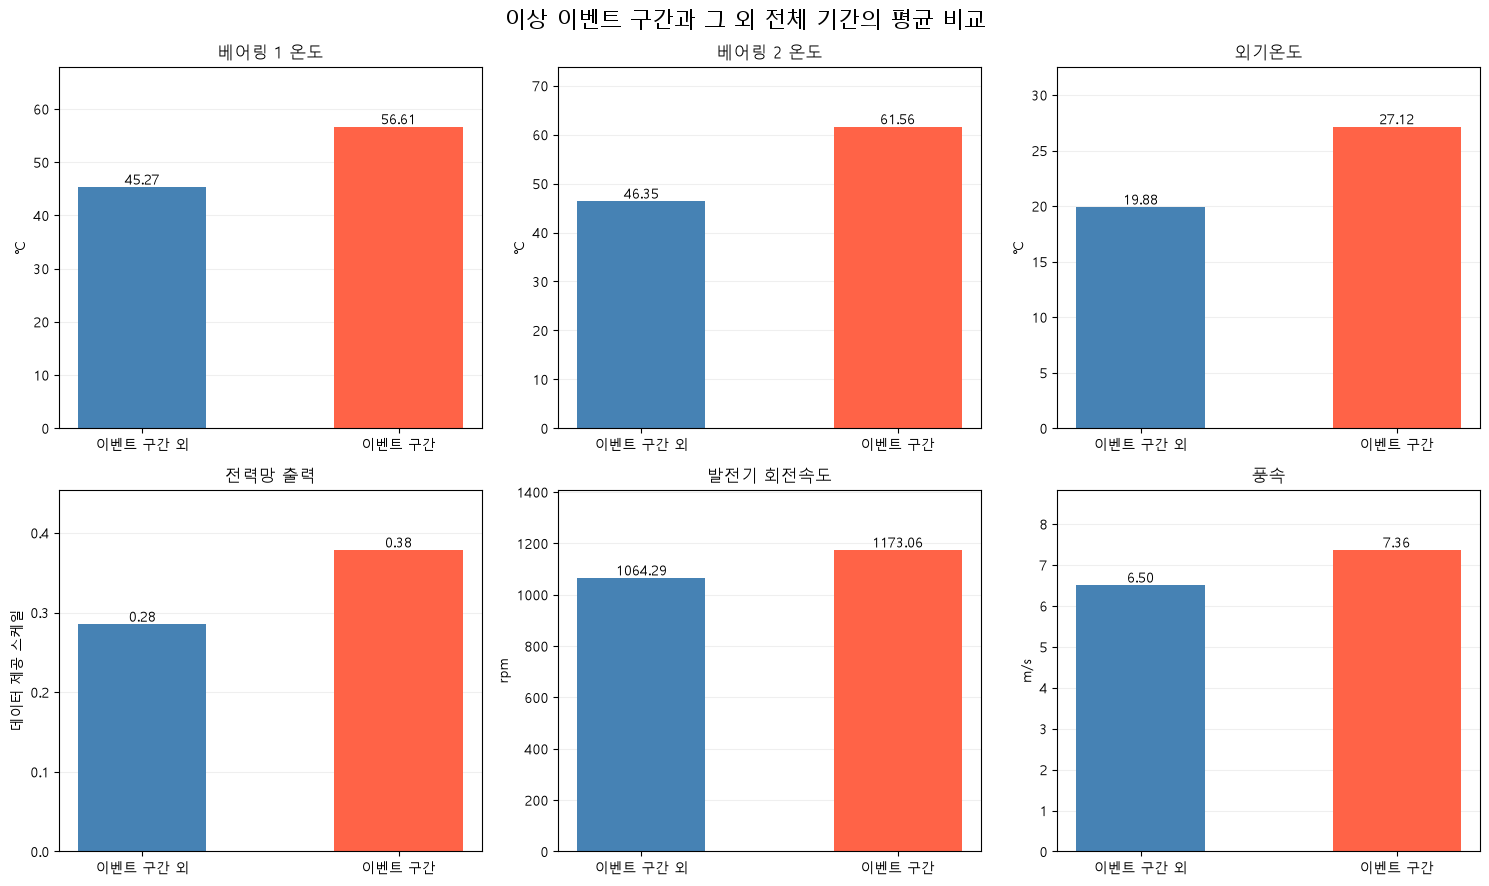

In [175]:
# 비교할 컬럼
cols = [
    '발전기베어링1_비구동측온도_평균',
    '발전기베어링2_구동측온도_평균',
    '외기온도_평균',
    '전력망출력_평균',
    '발전기회전속도_평균',
    '풍속_평균'
]

# 그래프 제목과 단위
titles = [
    '베어링 1 온도', '베어링 2 온도', '외기온도',
    '전력망 출력', '발전기 회전속도', '풍속'
]

units = ['℃', '℃', '℃', '데이터 제공 스케일', 'rpm', 'm/s']

# 구간별 평균 계산
평균 = df0.groupby('이벤트구분')[cols].mean()
평균 = 평균.loc[['이벤트 구간 외', '이벤트 구간']]

# 한글 표시 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i in range(len(cols)):
    ax = axes.flat[i]

    ax.bar(
        평균.index,
        평균[cols[i]],
        color=['steelblue', 'tomato'],
        width=0.5
    )

    ax.set_title(titles[i])
    ax.set_ylabel(units[i])
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

    # 막대 위에 평균값 표시
    for j in range(2):
        value = 평균.iloc[j, i]
        ax.text(j, value, f'{value:.2f}', ha='center', va='bottom')

    ax.margins(y=0.2)

fig.suptitle('이상 이벤트 구간과 그 외 전체 기간의 평균 비교', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
#7.	리포트 — 개요·전처리·발견·결론 4단 구조

# 풍력발전기 베어링 고장 관련 센서 데이터 탐색 보고서

## 1. 개요
풍력단지 A에 포함된 `0.csv`를 분석

이벤트 정보에는 발전기 베어링 고장 관련 이상 이벤트 1건이 기록

## 2. 전처리
세미콜론(`;`)을 구분자로 지정하여 CSV를 불러왔다. 센서 설명 파일을 참고해 컬럼명을 한글로 변경
결측치와 중복 여부를 확인


## 3. 발견
베어링 1·2 온도, 외기온도, 전력망 출력, 발전기 회전속도, 풍속을 비교 대상으로 선정

이벤트 발생기간 조금 차이를 보임

## 4. 결론
이벤트 구간에서 베어링 온도가 높아지는 현상을 확인했지만, 온도 상승을 고장 징후로 단정할 수는 없다.

아직 다른 csv 가많으니 다른 것도 봐야함. 

